#Deep Learning para visión de computadoras
##Lab 3 Segmentación semántica

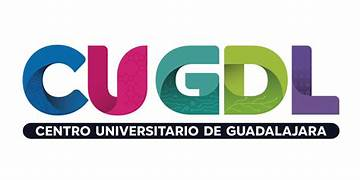

# Objetivos y alcance de la entrega

1. Implementar U-Net y verificar IoU/mIoU y Dice a partir de la matriz de confusión.
2. Comparar CE, Dice, CE + Dice, ponderación por clase y ablación de conexiones de salto.
3. Aplicar la arquitectura a Kvasir-SEG y comparar CNN estática frente a CNN-LSTM.
4. Segmentar hipocampo en MRI 3D y analizar la revisión de U-Net indicada.
5. Reproducir el experimento de clasificación desbalanceada: modelo base, pesos, sobremuestreo y selección de umbral.

**Protocolo:** semilla 2; particiones disjuntas; pesos y normalización estimados únicamente en entrenamiento. Cada comparación de Pets utiliza la misma inicialización, lotes, seis épocas y selección de checkpoint por mIoU de validación. Las conclusiones se generan desde las salidas ejecutadas. Una sola semilla no permite afirmar significancia estadística.

**Adaptaciones explícitas:** el desarrollo de segmentación usa PyTorch, como el notebook original. El tutorial de TensorFlow se contrasta conceptualmente; el apéndice de fraude sí usa TensorFlow/Keras. El enlace SharePoint del tutorial LISA devuelve HTTP 401 sin autenticación: se utiliza **MSD Task04_Hippocampus**, no LISA. Sus etiquetas son hipocampo anterior/posterior, no izquierdo/derecho. Carvana requiere acceso a la competencia Kaggle; se completa la actividad de otro dataset con Kvasir-SEG.

In [1]:
# Instalar solamente dependencias ausentes en el kernel activo (Colab o entorno local).
import importlib.util, subprocess, sys
dependencias = {"torch": "torch", "torchvision": "torchvision", "torchmetrics": "torchmetrics",
                "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "PIL": "Pillow",
                "nibabel": "nibabel", "sklearn": "scikit-learn", "tensorflow": "tensorflow"}
faltantes = [paquete for modulo,paquete in dependencias.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    if importlib.util.find_spec("pip") is None:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Dependencias disponibles en", sys.executable)

Dependencias disponibles en /Users/vikingo/Documents/UDG2/5toSem/DeepLearning/.venv/bin/python3


In [2]:
import time, copy, random, json
from pathlib import Path
from IPython.display import display, Markdown
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Dataset, Subset
import torchmetrics
import torchvision
import torchvision.transforms as T
from torchmetrics.classification import MulticlassJaccardIndex, MulticlassConfusionMatrix

SEED = 2
def fijar_semilla(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()
torch.set_num_threads(6)
if torch.backends.cudnn.is_available():
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE)
print("torch", torch.__version__, "· torchmetrics", torchmetrics.__version__)

DATA = Path("data")
DATA.mkdir(exist_ok=True)
RESULTADOS = Path("resultados")
RESULTADOS.mkdir(exist_ok=True)
print("Python y bibliotecas:", __import__("sys").version.split()[0], torchvision.__version__, np.__version__)

Dispositivo: mps · mps
torch 2.14.1 · torchmetrics 1.9.0
Python y bibliotecas: 3.11.16 0.29.1 2.4.6


---
# PARTE A

En clasificación, una imagen tiene **una** etiqueta. En segmentación semántica, una imagen de $H\times W$ tiene **$H\cdot W$ etiquetas**:

El conjunto de datos de mascotas Oxford- IIIT ( Parkhi et al, 2012 ). El conjunto de datos consta de imágenes de 37 razas de mascotas, con 200 imágenes por raza (~100 cada una en las divisiones de entrenamiento y prueba). Cada imagen incluye las etiquetas correspondientes y las máscaras de píxeles.

    El dataset contiene imágenes de mascotas y máscaras de segmentación de 3 clases:
    
    Clase 1: Mascota (Foreground)
    Clase 2: Fondo (Background)
    Clase 3: Borde / Contorno ambiguo\

In [3]:
TAM = 128
NOMBRES_CLASES = ["Mascota", "Fondo", "Borde"]
N_CLASES = len(NOMBRES_CLASES)

# Transformación para la imagen (RGB -> Normalización estándar de ImageNet)
transform_img = T.Compose([
    T.Resize((TAM, TAM)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformación para la máscara (Interpolación NEAREST para preservar enteros) reescalado, garantizando que no se generen valores intermedios artificiales entre categorías.
#Por conveniencia, reste 1 de la máscara de segmentación, lo que da como resultado etiquetas que son: {0, 1, 2}.
def transform_mask(mask):
    mask = mask.resize((TAM, TAM), resample=Image.NEAREST)
    mask_arr = np.array(mask, dtype=np.int64) - 1  # Pasar de {1,2,3} a {0,1,2}
    return torch.as_tensor(mask_arr, dtype=torch.long)

# Descargar dataset oficial vía torchvision
# Reutilizar la caché del proyecto si está completa.
PET_ROOT = next((p for p in [DATA, Path("../Actividades/data")]
                 if (p / "oxford-iiit-pet/images").is_dir()), DATA)
train_raw = torchvision.datasets.OxfordIIITPet(
    root=str(PET_ROOT), split="trainval", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)
test_raw = torchvision.datasets.OxfordIIITPet(
    root=str(PET_ROOT), split="test", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)

# Subconjuntos optimizados para una sesión interactiva de clase (rápida convergencia)
indices_pet = torch.randperm(len(train_raw), generator=torch.Generator().manual_seed(SEED)).tolist()
indices_train, indices_val = indices_pet[:1000], indices_pet[1000:1250]
assert not set(indices_train) & set(indices_val)
# Caché de tensores: cada imagen se decodifica una sola vez.
def cache_dataset(ds):
    pares = [ds[i] for i in range(len(ds))]
    return TensorDataset(torch.stack([p[0] for p in pares]), torch.stack([p[1] for p in pares]))
train_ds = cache_dataset(Subset(train_raw, indices_train))
val_ds = cache_dataset(Subset(train_raw, indices_val))
indices_test = torch.randperm(len(test_raw), generator=torch.Generator().manual_seed(SEED)).tolist()[:250]
test_ds = cache_dataset(Subset(test_raw, indices_test))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)

test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)
assert set(torch.unique(train_ds.tensors[1]).tolist()) == {0, 1, 2}
print(f"Entrenamiento: {len(train_ds)} | Validación: {len(val_ds)} | Prueba oficial: {len(test_ds)}")

Entrenamiento: 1000 | Validación: 250 | Prueba oficial: 250


máscaras reales codificadas mediante un mapa de color cualitativo (Verde = Mascota, Negro = Fondo, Rojo = Borde):

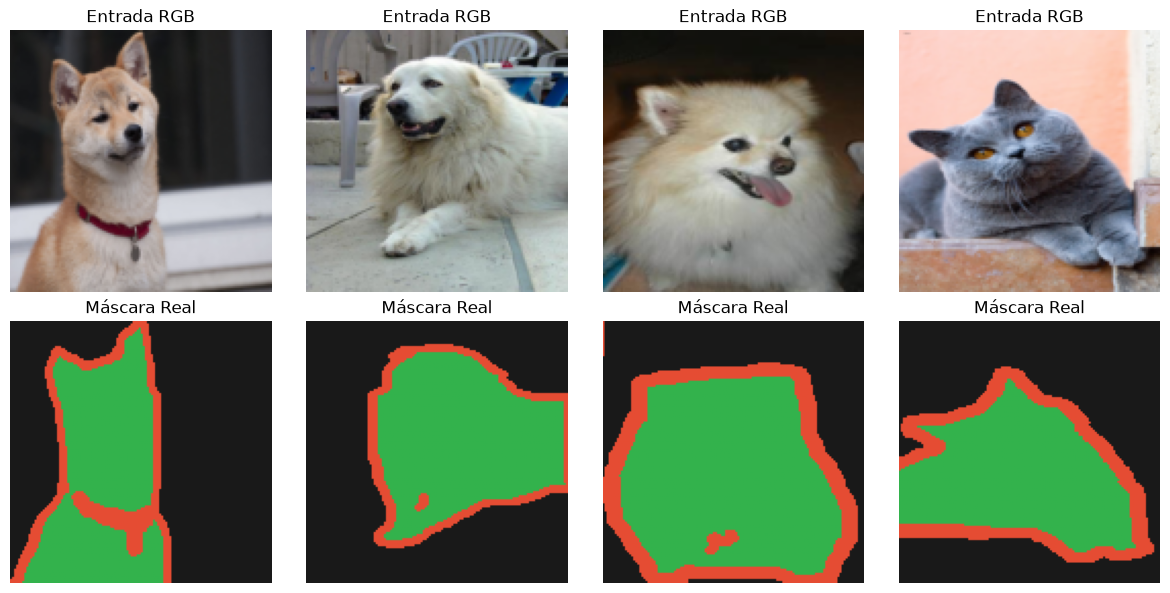

In [4]:
def desnormalizar(tensor):
    img = tensor.clone().cpu().permute(1, 2, 0).numpy()
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    return np.clip(img, 0, 1)

PALETA_PETS = np.array([[0.2, 0.7, 0.3], [0.1, 0.1, 0.1], [0.9, 0.3, 0.2]])

imgs, masks = next(iter(train_loader))
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Máscara Real")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

# 2. ARQUITECTURA DE LA RED: U-NET COMPACTA DESDE CEROLa red implementa una estructura simétrica compuesta por:   

1.   Bloque Doble de Convolución: Encapsula la secuencia $\text {Conv2D} \rightarrow \text{BatchNorm} \rightarrow \text{ReLU}$ por duplicado, manteniendo dimensiones espaciales mediante relleno (padding $= 1$).

2.   Trayectoria de Contracción (Encoder): Reduce periódicamente la resolución a la mitad con operaciones de agrupamiento máximo (MaxPool2d) mientras incrementa la profundidad de canales semánticos.   
3. Cuello de Botella (Bottleneck): El punto de mayor compresión espacial ($16 \times 16$) y máxima abstracción de características.   
4. Trayectoria de Expansión (Decoder): Aplica convoluciones transpuestas (ConvTranspose2d) con factor de escala $\times 2$ y realiza la fusión por concatenación (torch.cat) de las activaciones correspondientes del codificador.   
5. Capa de Salida: Una convolución $1 \times 1$ que reduce los 32 canales residuales a 3 logits correspondientes a las clases del problema.  

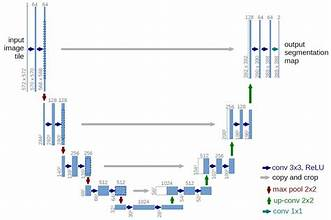

In [5]:
class BloqueDobleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class UNetCompacta(nn.Module):
    def __init__(self, in_channels=3, num_classes=3, use_skips=True):
        super().__init__()
        self.use_skips = use_skips
        # --- ENCODER ---
        self.enc1 = BloqueDobleConv(in_channels, 32)      # Entrada: 128x128
        self.pool1 = nn.MaxPool2d(2, 2)                   # -> 64x64

        self.enc2 = BloqueDobleConv(32, 64)               # -> 64x64
        self.pool2 = nn.MaxPool2d(2, 2)                   # -> 32x32

        self.enc3 = BloqueDobleConv(64, 128)              # -> 32x32
        self.pool3 = nn.MaxPool2d(2, 2)                   # -> 16x16

        # --- BOTTLENECK ---
        self.bottleneck = BloqueDobleConv(128, 256)       # -> 16x16

        # --- DECODER & SKIP CONNECTIONS ---
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2) # -> 32x32
        self.dec3 = BloqueDobleConv(256, 128)             # 128 (skip) + 128 = 256

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # -> 64x64
        self.dec2 = BloqueDobleConv(128, 64)              # 64 (skip) + 64 = 128

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # -> 128x128
        self.dec1 = BloqueDobleConv(64, 32)               # 32 (skip) + 32 = 64

        # Proyección final lineal a nivel de píxel
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Paso por el Encoder
        s1 = self.enc1(x)
        p1 = self.pool1(s1)

        s2 = self.enc2(p1)
        p2 = self.pool2(s2)

        s3 = self.enc3(p2)
        p3 = self.pool3(s3)

        # Cuello de botella
        b = self.bottleneck(p3)

        # Paso por el Decoder con Skip Connections (torch.cat)
        d3 = self.up3(b)
        d3 = torch.cat([d3, s3 if self.use_skips else torch.zeros_like(s3)], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2 if self.use_skips else torch.zeros_like(s2)], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1 if self.use_skips else torch.zeros_like(s1)], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

fijar_semilla()
modelo = UNetCompacta(in_channels=3, num_classes=3).to(DEVICE)
print("Arquitectura instanciada. Parámetros totales:", sum(p.numel() for p in modelo.parameters()))

Arquitectura instanciada. Parámetros totales: 1927075


---
# PARTE B

Sean $TP_c$, $FP_c$, $FN_c$ los píxeles de la clase $c$ acertados, falsamente asignados a $c$ y omitidos, respectivamente. Para cada clase:

$$\mathrm{IoU}_c=\frac{TP_c}{TP_c+FP_c+FN_c}\qquad \mathrm{Dice}_c=\frac{2\,TP_c}{2\,TP_c+FP_c+FN_c}\qquad \mathrm{mIoU}=\frac{1}{C}\sum_{c=1}^{C}\mathrm{IoU}_c$$

Todo sale de la **matriz de confusión** de píxeles: la diagonal contiene los $TP_c$; la suma de la fila $c$ menos la diagonal son los $FN_c$; la suma de la columna $c$ menos la diagonal son los $FP_c$. Aquí las filas son la clase real y las columnas la predicha.

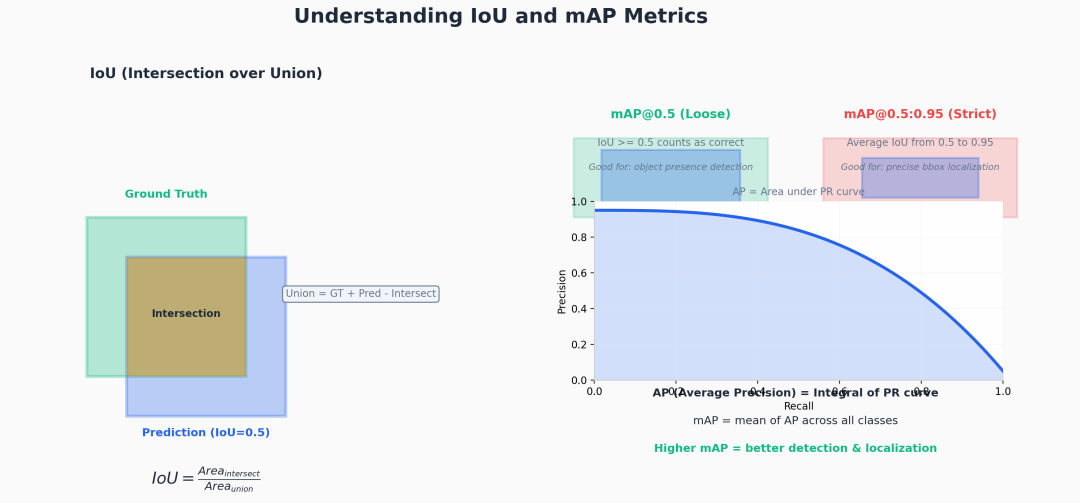

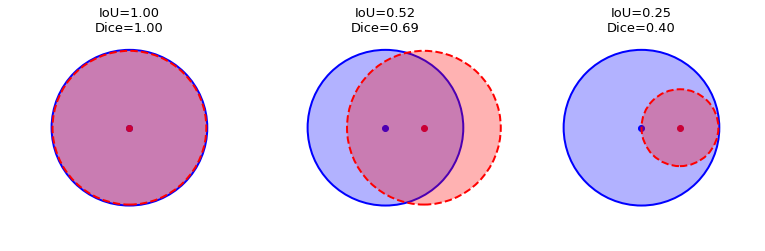

Revisar: https://ilmonteux.github.io/2019/05/10/segmentation-metrics.html


## Pérdidas

La entropía cruzada compara logits con etiquetas enteras por píxel. Se usa soft Dice multiclase:

$$D_c=\frac{2\sum_i p_{ic}t_{ic}+\epsilon}{\sum_i p_{ic}+\sum_i t_{ic}+\epsilon},\qquad
\mathcal L_{Dice}=1-\operatorname{media}_{b,c}D_{bc}.$$

Las probabilidades se obtienen con softmax. La máscara real es one-hot; no se binariza la predicción durante el entrenamiento. La pérdida híbrida es CE + Dice. Esta variante usa sumas sin cuadrados, exactamente como la implementación. El Dice duro de evaluación se calcula con argmax y la matriz de confusión; no equivale al soft Dice de entrenamiento.

In [6]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)

        # One-hot encoding de targets a dimensiones [B, C, H, W] (o [B, C, D, H, W] en 3D)
        targets_one_hot = F.one_hot(targets, num_classes=num_classes).movedim(-1, 1).float()

        # Aplanar dimensiones espaciales para el cálculo vectorial
        probs = probs.contiguous().view(probs.shape[0], num_classes, -1)
        targets_one_hot = targets_one_hot.contiguous().view(targets_one_hot.shape[0], num_classes, -1)

        interseccion = (probs * targets_one_hot).sum(dim=2)
        union = probs.sum(dim=2) + targets_one_hot.sum(dim=2)

        dice = (2. * interseccion + self.eps) / (union + self.eps)
        return 1.0 - dice.mean()

# Instanciación de pérdidas
ce_fn = nn.CrossEntropyLoss()
dice_fn = DiceLoss()

def loss_combinada(logits, targets):
    return ce_fn(logits, targets) + dice_fn(logits, targets)

In [7]:
# Evaluación común: acumular una sola matriz para todo el conjunto.
def evaluar_modelo(m, loader, n_clases, device=DEVICE):
    conf = torch.zeros(n_clases, n_clases, dtype=torch.int64)
    m.eval()
    with torch.no_grad():
        for x, y in loader:
            pred = m(x.to(device)).argmax(1).cpu()
            y = y.cpu()
            conf += torch.bincount((n_clases * y + pred).flatten(), minlength=n_clases**2).reshape(n_clases, n_clases)
    matriz = conf.numpy()
    tp = np.diag(matriz).astype(float)
    fp, fn = matriz.sum(0) - tp, matriz.sum(1) - tp
    iou = np.divide(tp, tp + fp + fn, out=np.zeros(n_clases), where=(tp + fp + fn) > 0)
    dice = np.divide(2*tp, 2*tp + fp + fn, out=np.zeros(n_clases), where=(2*tp + fp + fn) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros(n_clases), where=(tp + fn) > 0)
    return {"cm": matriz, "iou": iou, "dice": dice, "recall": recall,
            "miou": float(iou.mean()), "accuracy": float(tp.sum()/matriz.sum())}

def entrenar_modelo(m, loader, valid, loss_fn, n_clases, nombre, epochs=6, device=DEVICE):
    # Reiniciar el generador asegura idéntico orden de lotes entre configuraciones.
    fijar_semilla()
    if loader.generator is not None:
        loader.generator.manual_seed(SEED)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    history, best_score, best_state = [], -1.0, None
    for ep in range(1, epochs+1):
        start = time.time(); m.train(); total, count = 0.0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(m(x), y)
            assert torch.isfinite(loss).item(), "Pérdida no finita"
            loss.backward(); opt.step()
            total += loss.item()*len(x); count += len(x)
        result = evaluar_modelo(m, valid, n_clases, device)
        val_total, val_count = 0.0, 0
        with torch.no_grad():
            for x, y in valid:
                val_total += loss_fn(m(x.to(device)), y.to(device)).item()*len(x)
                val_count += len(x)
        history.append({"epoca": ep, "loss_train": total/count, "loss_val": val_total/val_count,
                        "miou_val": result["miou"], "segundos": time.time()-start})
        if result["miou"] > best_score:
            best_score, best_epoch = result["miou"], ep
            best_state = {k: v.detach().cpu().clone() for k,v in m.state_dict().items()}
        print(f"{nombre} | {ep}/{epochs} | loss {total/count:.4f} | val mIoU {result['miou']:.4f} | {time.time()-start:.1f}s", flush=True)
    m.load_state_dict(best_state)
    return pd.DataFrame(history), best_epoch

def tabla_metricas(result, nombres):
    return pd.DataFrame({"Clase": nombres, "IoU": result["iou"], "Dice": result["dice"], "Recall": result["recall"]})

def mostrar_segmentaciones(m, loader, paleta, titulo, device=DEVICE):
    x, y = next(iter(loader)); m.eval()
    with torch.no_grad():
        pred = m(x.to(device)).argmax(1).cpu()
    fig, axs = plt.subplots(3, 4, figsize=(12,8))
    for i in range(4):
        for row, (img, text) in enumerate([(desnormalizar(x[i]), "Imagen"), (paleta[y[i]], "Real"), (paleta[pred[i]], titulo)]):
            axs[row,i].imshow(img); axs[row,i].set_title(text); axs[row,i].axis("off")
    plt.tight_layout(); plt.show()

# Pruebas numéricas de métricas y pérdidas, sin descargar datos adicionales.
perfect = torch.tensor([[[[8., -8.]], [[-8., 8.]]]])
target = torch.tensor([[[0,1]]])
assert dice_fn(perfect, target).item() < 1e-5
assert dice_fn(-perfect, target).item() > .99
assert dice_fn(torch.randn(2,3,8,8,8), torch.randint(0,3,(2,8,8,8))).isfinite()
assert modelo(torch.zeros(1,3,TAM,TAM,device=DEVICE)).shape == (1,3,TAM,TAM)
print("Comprobaciones de formas y Dice: correctas")

Comprobaciones de formas y Dice: correctas


#ENTRENAMIENTO

In [8]:
EPOCHS = 6
# Guardar el estado inicial para todos los experimentos controlados.
estado_inicial = {k:v.detach().cpu().clone() for k,v in modelo.state_dict().items()}
hist_base, mejor_epoca_base = entrenar_modelo(modelo, train_loader, val_loader, loss_combinada, N_CLASES, "CE + Dice", EPOCHS)
base = evaluar_modelo(modelo, val_loader, N_CLASES)
historias = {"CE + Dice": hist_base}
modelos_pet = {"CE + Dice": modelo}
evaluaciones_pet = {"CE + Dice": base}
epocas_pet = {"CE + Dice": mejor_epoca_base}

CE + Dice | 1/6 | loss 1.2749 | val mIoU 0.4492 | 4.6s


CE + Dice | 2/6 | loss 1.0626 | val mIoU 0.4573 | 4.4s


CE + Dice | 3/6 | loss 1.0254 | val mIoU 0.5229 | 4.4s


CE + Dice | 4/6 | loss 0.9150 | val mIoU 0.5666 | 4.4s


CE + Dice | 5/6 | loss 0.8335 | val mIoU 0.5801 | 4.4s


CE + Dice | 6/6 | loss 0.8027 | val mIoU 0.5620 | 4.4s


IoU, mIoU Y MATRIZ DE CONFUSIÓN

Calculo de forma desacoplada el índice de Jaccard (Intersection over Union) para cada una de las clases, su promedio macro (mIoU) y la matriz de confusión espacial de píxeles empleando torchmetrics:   $$\text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

In [9]:
metric_iou_clase = MulticlassJaccardIndex(num_classes=N_CLASES, average=None).to(DEVICE)
metric_iou_macro = MulticlassJaccardIndex(num_classes=N_CLASES, average="macro").to(DEVICE)
metric_confusion = MulticlassConfusionMatrix(num_classes=N_CLASES).to(DEVICE)

modelo.eval()
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = modelo(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase.update(preds, masks)
        metric_iou_macro.update(preds, masks)
        metric_confusion.update(preds, masks)

ious = metric_iou_clase.compute().cpu().numpy()
miou = metric_iou_macro.compute().item()
cm = metric_confusion.compute().cpu().numpy()

tabla_eval = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU (Jaccard)": [round(val, 4) for val in ious]
})
display(tabla_eval)
print(f"\nMean IoU (mIoU): {miou:.4f}")

print("\nMatriz de Confusión de Píxeles:\n", cm)

,Clase,IoU (Jaccard)
0,Mascota,0.6072
1,Fondo,0.7811
2,Borde,0.3522



Mean IoU (mIoU): 0.5801

Matriz de Confusión de Píxeles:
 [[ 895477  260005  160556]
 [  81802 2107625  104907]
 [  77021  144105  264502]]


In [10]:
# IoU y Dice "a mano" desde la matriz de confusión (filas = real, columnas = predicha)
TP = np.diag(cm).astype(float)
FN = cm.sum(axis=1) - TP
FP = cm.sum(axis=0) - TP
iou_manual  = TP / (TP + FP + FN)
dice_manual = 2 * TP / (2 * TP + FP + FN)

tabla_manual = pd.DataFrame({"Clase": NOMBRES_CLASES, "TP": TP.astype(int), "FP": FP.astype(int), "FN": FN.astype(int),
                             "IoU manual": iou_manual.round(4), "IoU torchmetrics": ious.round(4), "Dice": dice_manual.round(4)})
display(tabla_manual)
print(f"mIoU manual = {iou_manual.mean():.4f} | mIoU torchmetrics = {miou:.4f}")
assert np.allclose(iou_manual, ious, atol=1e-4), "El IoU manual no coincide con torchmetrics"

,Clase,TP,FP,FN,IoU manual,IoU torchmetrics,Dice
0,Mascota,895477,158823,420561,0.6072,0.6072,0.7556
1,Fondo,2107625,404110,186709,0.7811,0.7811,0.8771
2,Borde,264502,265463,221126,0.3522,0.3522,0.5209


mIoU manual = 0.5801 | mIoU torchmetrics = 0.5801


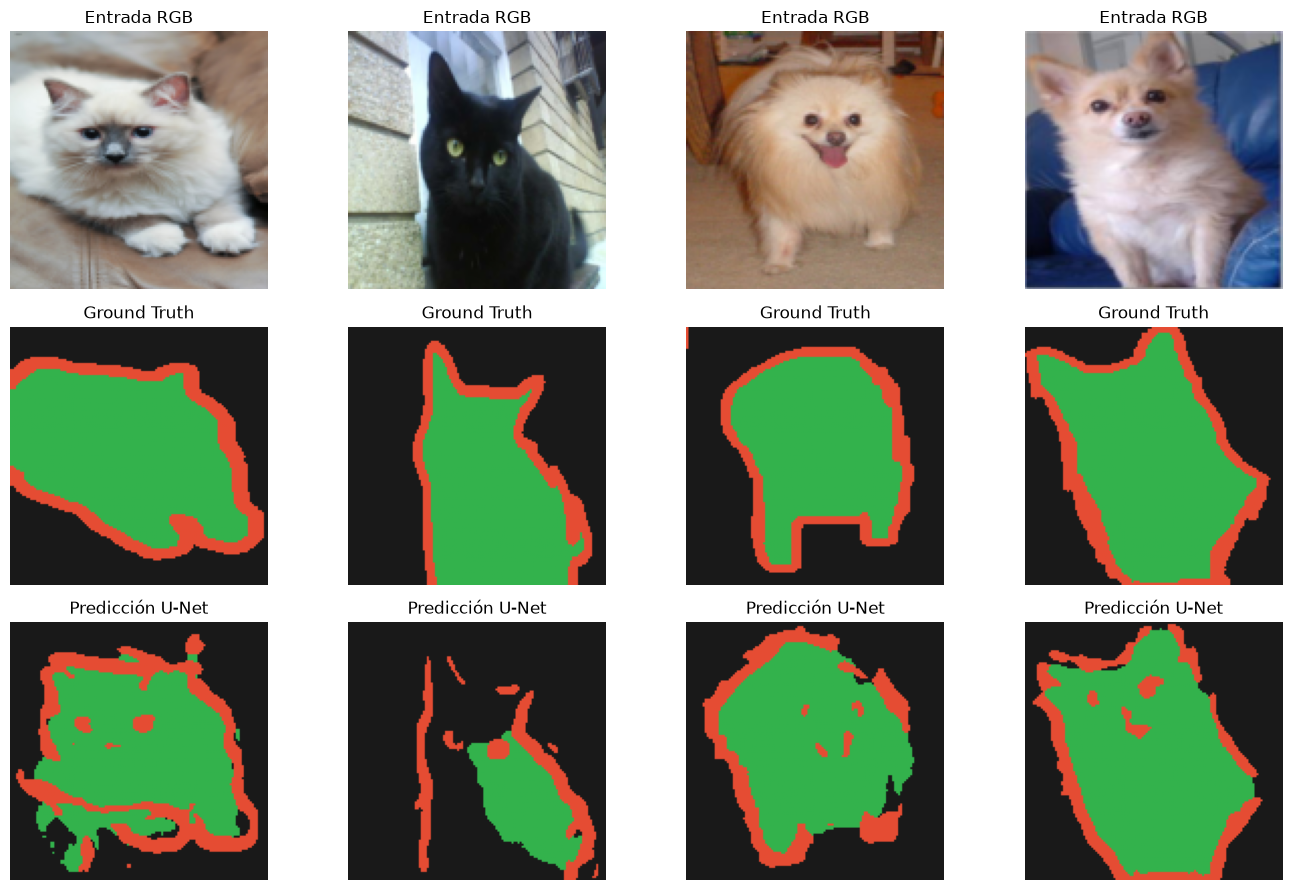

In [11]:
imgs, masks = next(iter(val_loader))
imgs_dev = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_dev).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(PALETA_PETS[preds[i].numpy()])
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")
plt.tight_layout()
plt.show()

### Actividad
Clases desequilibradas y ponderación de clases

Los conjuntos de datos para segmentación semántica pueden estar muy desequilibrados; esto significa que los píxeles correspondientes a determinadas clases pueden aparecer con mayor frecuencia en las imágenes que los de otras clases. Dado que los problemas de segmentación pueden abordarse como problemas de clasificación a nivel de píxel, es posible gestionar este desequilibrio mediante la ponderación de la función de pérdida. Se trata de una solución sencilla y elegante para este tipo de situaciones. Para obtener más información, consulte el tutorial sobre [Classification on imbalanced data](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data) tutorial to learn more.

To [avoid ambiguity](https://github.com/keras-team/keras/issues/3653#issuecomment-243939748), `Model.fit` does not support the `class_weight` argument for targets with 3+ dimensions.

,clase,píxeles,fracción
0,Mascota,4817124,0.2940
1,Fondo,9700710,0.5921
2,Borde,1866166,0.1139


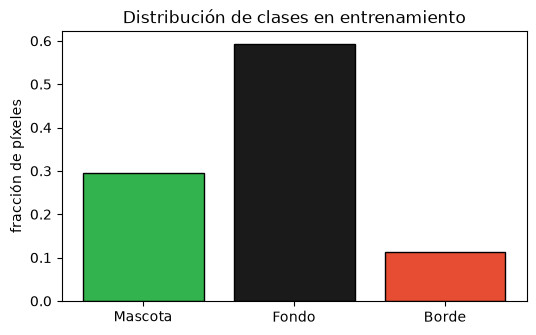

El fondo ocupa 59.2 % de los píxeles y el borde solo 11.4 %.


In [12]:
# Gráfica de barras de desbalance (máscaras de entrenamiento)
Y_ent = torch.stack([train_ds[i][1] for i in range(len(train_ds))])
conteo = torch.bincount(Y_ent.flatten(), minlength=N_CLASES).numpy()
frac = conteo / conteo.sum()
tabla_px = pd.DataFrame({"clase": NOMBRES_CLASES, "píxeles": conteo, "fracción": frac.round(4)})
display(tabla_px)

plt.figure(figsize=(6, 3.5)); plt.bar(NOMBRES_CLASES, frac, color=PALETA_PETS, edgecolor="k")
plt.ylabel("fracción de píxeles"); plt.title("Distribución de clases en entrenamiento"); plt.show()
print(f"El fondo ocupa {frac[1]*100:.1f} % de los píxeles y el borde solo {frac[2]*100:.1f} %.")

Con la exactitud obtenida explica por qué la exactitud de píxeles **no es una métrica adecuada** para segmentación cuando una clase domina.

In [13]:
# Exactitud de píxeles del modelo vs. un "modelo" trivial que siempre predice la clase dominante
acc_modelo = TP.sum() / cm.sum()
clase_dom = int(frac.argmax())   # Elegida exclusivamente con entrenamiento.
acc_trivial = cm.sum(axis=1)[clase_dom] / cm.sum()   # Evaluada en la misma validación.
iou_trivial = np.zeros(N_CLASES); iou_trivial[clase_dom] = acc_trivial
print(f"Exactitud U-Net: {acc_modelo:.4f} | Exactitud siempre {NOMBRES_CLASES[clase_dom]}: {acc_trivial:.4f}")
display(Markdown(f"**Respuesta:** predecir siempre fondo obtiene {acc_trivial:.1%} en validación sin observar la imagen. "
                 f"La U-Net obtiene {acc_modelo:.1%}, pero su IoU de borde es {ious[2]:.4f}. "
                 f"El trivial tiene mIoU {iou_trivial.mean():.4f} y cero IoU en las demás clases. "
                 "La exactitud cuenta más la clase grande; IoU y Dice por clase revelan los errores en las minoritarias."))

Exactitud U-Net: 0.7978 | Exactitud siempre Fondo: 0.5601


**Respuesta:** predecir siempre fondo obtiene 56.0% en validación sin observar la imagen. La U-Net obtiene 79.8%, pero su IoU de borde es 0.3522. El trivial tiene mIoU 0.1867 y cero IoU en las demás clases. La exactitud cuenta más la clase grande; IoU y Dice por clase revelan los errores en las minoritarias.

In [14]:
# Ponderación de clases: peso inversamente proporcional a la frecuencia de píxeles
pesos = torch.tensor(1.0 / frac, dtype=torch.float32)
pesos = (pesos / pesos.sum() * N_CLASES).to(DEVICE)       # normalizados para que sumen N_CLASES
print("Pesos por clase:", dict(zip(NOMBRES_CLASES, pesos.cpu().numpy().round(3))))
ce_pond = nn.CrossEntropyLoss(weight=pesos)
def loss_ponderada(logits, targets):
    return ce_pond(logits, targets) + dice_fn(logits, targets)

fijar_semilla()
modelo_pond = UNetCompacta().to(DEVICE)
modelo_pond.load_state_dict(estado_inicial)
hist_pond, ep_pond = entrenar_modelo(modelo_pond, train_loader, val_loader, loss_ponderada, N_CLASES, "CE ponderada + Dice", EPOCHS)
pond = evaluar_modelo(modelo_pond, val_loader, N_CLASES)
historias["CE ponderada + Dice"] = hist_pond
modelos_pet["CE ponderada + Dice"] = modelo_pond
evaluaciones_pet["CE ponderada + Dice"] = pond
epocas_pet["CE ponderada + Dice"] = ep_pond
comparacion = pd.DataFrame({"Clase": NOMBRES_CLASES, "IoU sin pesos": ious, "IoU con pesos": pond["iou"],
                           "Recall sin pesos": base["recall"], "Recall con pesos": pond["recall"]})
display(comparacion.round(4))
display(Markdown(f"**Resultado observado:** mIoU {base['miou']:.4f} sin pesos y {pond['miou']:.4f} con pesos; "
                 f"IoU de borde {base['iou'][2]:.4f} y {pond['iou'][2]:.4f}, respectivamente. "
                 "Ponderar modifica el costo de error de cada clase; su efecto se evalúa, no se presupone. Una corrida por configuración."))

Pesos por clase: {'Mascota': np.float32(0.736), 'Fondo': np.float32(0.365), 'Borde': np.float32(1.899)}


CE ponderada + Dice | 1/6 | loss 1.3950 | val mIoU 0.4202 | 4.4s


CE ponderada + Dice | 2/6 | loss 1.1513 | val mIoU 0.5222 | 4.4s


CE ponderada + Dice | 3/6 | loss 1.0549 | val mIoU 0.5307 | 4.4s


CE ponderada + Dice | 4/6 | loss 0.9750 | val mIoU 0.5619 | 4.4s


CE ponderada + Dice | 5/6 | loss 0.9023 | val mIoU 0.5888 | 4.4s


CE ponderada + Dice | 6/6 | loss 0.8755 | val mIoU 0.5189 | 4.3s


,Clase,IoU sin pesos,IoU con pesos,Recall sin pesos,Recall con pesos
0,Mascota,0.6072,0.6189,0.6804,0.6874
1,Fondo,0.7811,0.7797,0.9186,0.8665
2,Borde,0.3522,0.3679,0.5447,0.7132


**Resultado observado:** mIoU 0.5801 sin pesos y 0.5888 con pesos; IoU de borde 0.3522 y 0.3679, respectivamente. Ponderar modifica el costo de error de cada clase; su efecto se evalúa, no se presupone. Una corrida por configuración.

## Comparación de pérdidas y ablación de conexiones

Se compara CE, Dice y CE + Dice sin cambiar arquitectura, inicialización ni orden de datos. Para aislar la información de los saltos, la variante **sin saltos** concatena ceros en lugar de las activaciones del encoder: conserva forma, número de parámetros y pesos iniciales. No es una comparación de eficiencia con un decoder más pequeño. Se reporta el mejor checkpoint de validación entre las mismas seis épocas; la prueba oficial se consulta después de seleccionar la configuración.

CE | 1/6 | loss 0.7351 | val mIoU 0.4148 | 4.3s


CE | 2/6 | loss 0.5995 | val mIoU 0.4355 | 4.3s


CE | 3/6 | loss 0.5748 | val mIoU 0.4471 | 4.3s


CE | 4/6 | loss 0.5251 | val mIoU 0.5084 | 4.3s


CE | 5/6 | loss 0.4763 | val mIoU 0.5803 | 930.6s


CE | 6/6 | loss 0.4510 | val mIoU 0.5775 | 4.3s


... (9 outputs left out)

Sin saltos (CE + Dice) | 4/6 | loss 0.8994 | val mIoU 0.5424 | 397.9s


Sin saltos (CE + Dice) | 5/6 | loss 0.8216 | val mIoU 0.5925 | 4.5s


Sin saltos (CE + Dice) | 6/6 | loss 0.7792 | val mIoU 0.5871 | 4.4s


,Experimento,mIoU val,Dice macro val,IoU mascota,IoU fondo,IoU borde,Mejor época,Parámetros
0,CE + Dice,0.5801,0.7178,0.6072,0.7811,0.3522,5,1927075
1,CE ponderada + Dice,0.5888,0.7262,0.6189,0.7797,0.3679,5,1927075
2,CE,0.5803,0.7102,0.6612,0.7852,0.2945,5,1927075
3,Dice,0.6060,0.7380,0.6632,0.7916,0.3632,6,1927075
4,Sin saltos (CE + Dice),0.5925,0.7247,0.6504,0.7914,0.3355,5,1927075


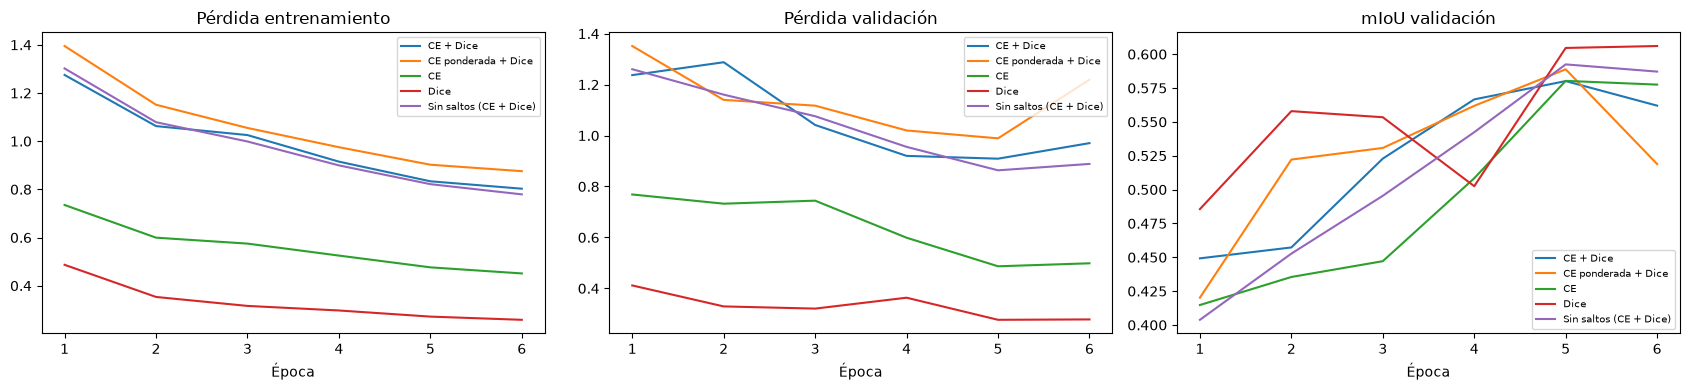

,Clase,IoU,Dice,Recall
0,Mascota,0.6824,0.8112,0.8497
1,Fondo,0.8175,0.8996,0.8963
2,Borde,0.3865,0.5575,0.5028


**Conclusión:** mejor configuración por validación: **Dice**. En el subconjunto aleatorio de 250 imágenes de la prueba oficial: mIoU **0.6288**. La diferencia con saltos menos sin saltos es -0.0123 de mIoU en validación. Los saltos transportan información espacial del encoder; el signo y magnitud medidos corresponden a este presupuesto de entrenamiento. Las pérdidas CE y Dice tienen escalas distintas, por lo que sus valores absolutos no se comparan como calidad: se usa la misma métrica IoU. No se atribuye significancia estadística con una sola semilla.

In [15]:
for nombre, perdida, saltos in [("CE", ce_fn, True), ("Dice", dice_fn, True), ("Sin saltos (CE + Dice)", loss_combinada, False)]:
    fijar_semilla()
    m = UNetCompacta(use_skips=saltos).to(DEVICE)
    m.load_state_dict(estado_inicial)
    assert all(torch.equal(v.cpu(), estado_inicial[k]) for k,v in m.state_dict().items())
    hist, ep = entrenar_modelo(m, train_loader, val_loader, perdida, N_CLASES, nombre, EPOCHS)
    historias[nombre], modelos_pet[nombre] = hist, m
    evaluaciones_pet[nombre] = evaluar_modelo(m, val_loader, N_CLASES)
    epocas_pet[nombre] = ep

tabla_experimentos = pd.DataFrame([
    {"Experimento": name, "mIoU val": r["miou"], "Dice macro val": float(r["dice"].mean()),
     "IoU mascota": r["iou"][0], "IoU fondo": r["iou"][1], "IoU borde": r["iou"][2],
     "Mejor época": epocas_pet[name], "Parámetros": sum(p.numel() for p in modelos_pet[name].parameters())}
    for name,r in evaluaciones_pet.items()])
display(tabla_experimentos.round(4))
tabla_experimentos.to_csv(RESULTADOS / "pets_comparacion.csv", index=False)
fig, axs = plt.subplots(1,3,figsize=(17,4))
for name,h in historias.items():
    axs[0].plot(h.epoca,h.loss_train,label=name)
    axs[1].plot(h.epoca,h.loss_val,label=name)
    axs[2].plot(h.epoca,h.miou_val,label=name)
for ax,title in zip(axs,["Pérdida entrenamiento", "Pérdida validación", "mIoU validación"]):
    ax.set_title(title); ax.set_xlabel("Época"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
mejor_nombre = tabla_experimentos.loc[tabla_experimentos["mIoU val"].idxmax(), "Experimento"]
test_pet = evaluar_modelo(modelos_pet[mejor_nombre], test_loader, N_CLASES)
display(tabla_metricas(test_pet, NOMBRES_CLASES).round(4))
delta_saltos = base["miou"] - evaluaciones_pet["Sin saltos (CE + Dice)"]["miou"]
display(Markdown(f"**Conclusión:** mejor configuración por validación: **{mejor_nombre}**. "
                 f"En el subconjunto aleatorio de 250 imágenes de la prueba oficial: mIoU **{test_pet['miou']:.4f}**. "
                 f"La diferencia con saltos menos sin saltos es {delta_saltos:+.4f} de mIoU en validación. "
                 "Los saltos transportan información espacial del encoder; el signo y magnitud medidos corresponden a este presupuesto de entrenamiento. "
                 "Las pérdidas CE y Dice tienen escalas distintas, por lo que sus valores absolutos no se comparan como calidad: se usa la misma métrica IoU. "
                 "No se atribuye significancia estadística con una sola semilla."))

### Actividad
Otros datasets
[Carvana](https://www.kaggle.com/c/carvana-image-masking-challenge/overview) image masking challenge hosted on Kaggle.

DSB 2018
# https://datasets.simula.no/kvasir-seg/
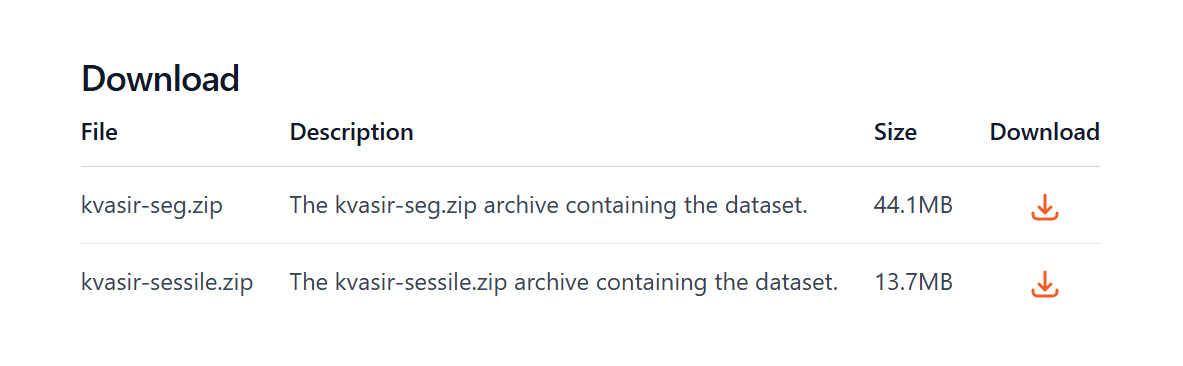

### Otro dataset: Kvasir-SEG

Se usa Kvasir-SEG (imágenes de endoscopia y máscaras de pólipos), con 70 % entrenamiento, 15 % validación y 15 % prueba, partición aleatoria fija por imagen. Se mantiene U-Net y CE + Dice; solo cambia la salida a dos clases. Los porcentajes de píxeles se estiman por separado para cada partición.

**Carvana:** la competencia Kaggle requiere cuenta y aceptar sus reglas. Con acceso, puede descargarse con `kaggle competitions download -c carvana-image-masking-challenge`. Esta entrega ejecuta Kvasir-SEG como alternativa pública; no afirma haber ejecutado Carvana. **DSB 2018 y Kvasir-SEG son datasets distintos**; el enlace original de esta actividad corresponde a Kvasir-SEG.

,Clase,Fracción train,Fracción val,Fracción test
0,Fondo,0.848263,0.838177,0.843618
1,Pólipo,0.151737,0.161823,0.156382


Kvasir | 1/6 | loss 0.9586 | val mIoU 0.5693 | 3.4s


Kvasir | 2/6 | loss 0.7452 | val mIoU 0.5625 | 3.1s


Kvasir | 3/6 | loss 0.6814 | val mIoU 0.5833 | 3.0s


Kvasir | 4/6 | loss 0.6390 | val mIoU 0.6263 | 3.1s


Kvasir | 5/6 | loss 0.5939 | val mIoU 0.6280 | 3.1s


Kvasir | 6/6 | loss 0.5692 | val mIoU 0.6068 | 3.0s


,Clase,IoU,Dice,Recall
0,Fondo,0.8691,0.9299,0.9447
1,Pólipo,0.4085,0.5800,0.5303


**Prueba Kvasir:** mIoU 0.6388; IoU de pólipo 0.4085; exactitud 0.8799; exactitud siempre fondo 0.8436, evaluadas en las mismas imágenes. La presencia de fondo hace necesario examinar el pólipo por separado. Esta partición es por imagen: no se dispone aquí de identificadores de paciente para demostrar independencia por paciente.

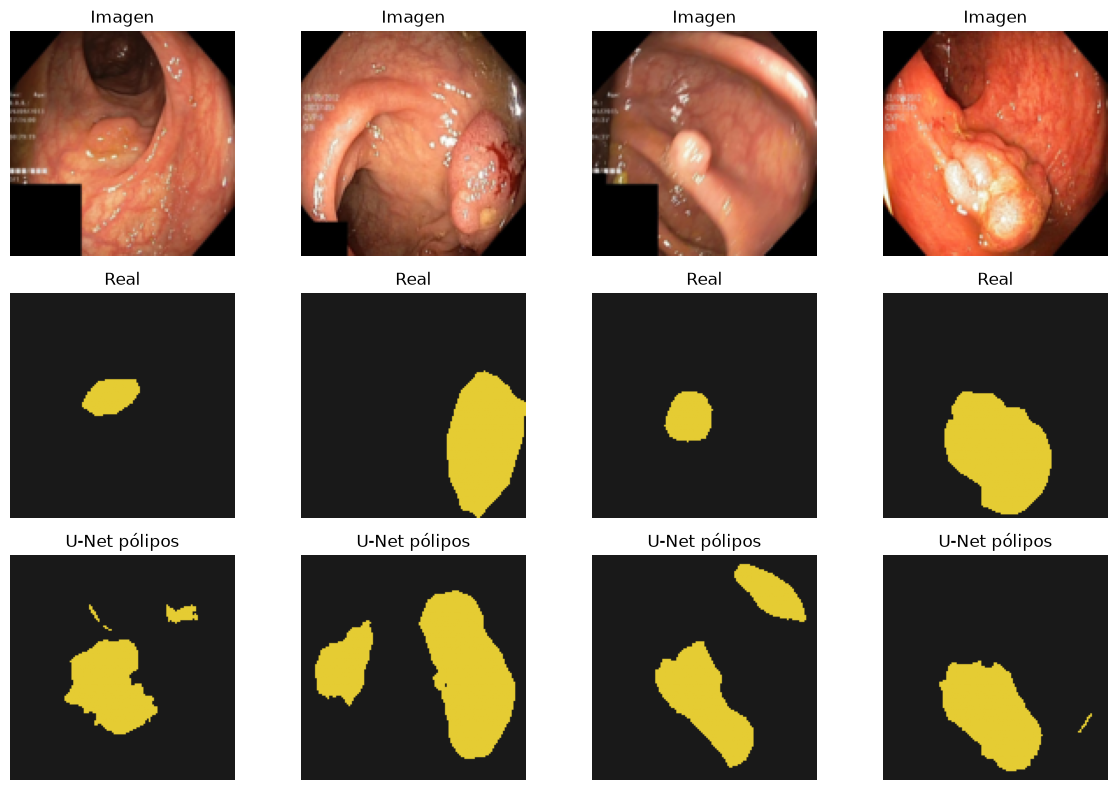

In [16]:
import urllib.request, zipfile, tarfile
KVASIR_DIR = next((p for p in [DATA / "kvasir", Path("../Actividades/data/kvasir")]
                   if (p / "Kvasir-SEG/images").is_dir()), DATA / "kvasir")
KVASIR_DIR.mkdir(parents=True,exist_ok=True)
if not (KVASIR_DIR / "Kvasir-SEG/images").is_dir():
    archivo = KVASIR_DIR / "kvasir-seg.zip"
    urllib.request.urlretrieve("https://datasets.simula.no/downloads/kvasir-seg.zip",archivo)
    with zipfile.ZipFile(archivo) as z:
        z.extractall(KVASIR_DIR)
raiz_k = KVASIR_DIR / "Kvasir-SEG"
nombres_k = sorted(p.name for p in (raiz_k / "images").glob("*.jpg"))
pares_k = []
for nombre in nombres_k:
    with Image.open(raiz_k / "images" / nombre) as im:
        x = transform_img(im.convert("RGB"))
    with Image.open(raiz_k / "masks" / nombre) as im:
        y = torch.from_numpy((np.array(im.convert("L").resize((TAM,TAM), Image.NEAREST)) > 127).astype(np.int64))
    pares_k.append((x,y))
X_k = torch.stack([p[0] for p in pares_k]); Y_k = torch.stack([p[1] for p in pares_k])
perm_k = torch.randperm(len(pares_k),generator=torch.Generator().manual_seed(SEED))
tr_idx,va_idx,te_idx = perm_k[:700],perm_k[700:850],perm_k[850:]
assert not set(tr_idx.tolist()) & set(va_idx.tolist())
assert not set(tr_idx.tolist()) & set(te_idx.tolist())
assert not set(va_idx.tolist()) & set(te_idx.tolist())
tr_k = DataLoader(TensorDataset(X_k[tr_idx],Y_k[tr_idx]),batch_size=16,shuffle=True,generator=torch.Generator().manual_seed(SEED))
va_k = DataLoader(TensorDataset(X_k[va_idx],Y_k[va_idx]),batch_size=16)
te_k = DataLoader(TensorDataset(X_k[te_idx],Y_k[te_idx]),batch_size=16)
NOMBRES_K = ["Fondo", "Pólipo"]; PALETA_K = np.array([[.1,.1,.1],[.9,.8,.2]])
display(pd.DataFrame({"Clase": NOMBRES_K,
    "Fracción train": torch.bincount(Y_k[tr_idx].flatten(),minlength=2).numpy()/Y_k[tr_idx].numel(),
    "Fracción val": torch.bincount(Y_k[va_idx].flatten(),minlength=2).numpy()/Y_k[va_idx].numel(),
    "Fracción test": torch.bincount(Y_k[te_idx].flatten(),minlength=2).numpy()/Y_k[te_idx].numel()}))
fijar_semilla(); modelo_k = UNetCompacta(num_classes=2).to(DEVICE)
hist_k,ep_k = entrenar_modelo(modelo_k,tr_k,va_k,loss_combinada,2,"Kvasir",EPOCHS)
resultado_k = evaluar_modelo(modelo_k,te_k,2)
display(tabla_metricas(resultado_k,NOMBRES_K).round(4))
trivial_k = resultado_k["cm"].sum(1)[0]/resultado_k["cm"].sum()
display(Markdown(f"**Prueba Kvasir:** mIoU {resultado_k['miou']:.4f}; IoU de pólipo {resultado_k['iou'][1]:.4f}; "
                 f"exactitud {resultado_k['accuracy']:.4f}; exactitud siempre fondo {trivial_k:.4f}, evaluadas en las mismas imágenes. "
                 "La presencia de fondo hace necesario examinar el pólipo por separado. Esta partición es por imagen: no se dispone aquí de identificadores de paciente para demostrar independencia por paciente."))
mostrar_segmentaciones(modelo_k,te_k,PALETA_K,"U-Net pólipos")

---
# PARTE C — Secuencias de video: CNN estática vs. CNN-LSTM

Dataset en línea: **Moving MNIST** (Srivastava et al., 2015), 10 000 secuencias de 20 cuadros de $64\times64$ con dígitos en movimiento (se descarga con `torchvision`).

Tarea: segmentar el dígito (máscara binaria) en el **último cuadro**. Para que la información temporal importe, la entrada tiene ruido gaussiano y el último cuadro tiene un **parche ocluido** de $24\times24$.

- **CNN estática:** solo ve el último cuadro (ruidoso y ocluido).
- **CNN-LSTM:** la misma CNN extrae rasgos de cada cuadro y una LSTM los integra en el tiempo, en cada posición espacial, antes del decodificador.

**Criterio de interpretación:** si la CNN estática obtiene IoU de dígito cero, se trata de un fallo de aprendizaje con este presupuesto. La ventaja de la CNN-LSTM frente a esa base no demuestra por sí sola que la diferencia provenga exclusivamente de memoria temporal. Para aislarla mejor habría que repetir el entrenamiento, aumentar el presupuesto de ambos modelos y comparar también con una CNN de capacidad equivalente.

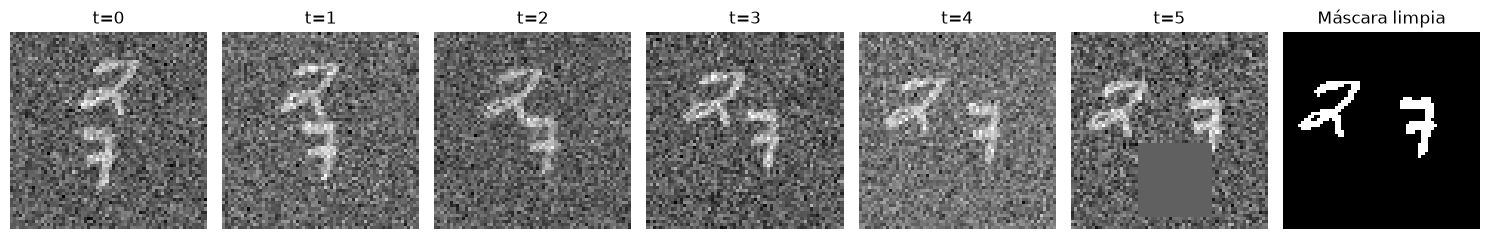

In [17]:
# Datos: Moving MNIST -> secuencias ruidosas con oclusión en el último cuadro
mm = torchvision.datasets.MovingMNIST(root=str(DATA), download=True)
T_SEQ, N_VID, OCL = 6, 1000, 24
# Subconjunto fijo para limitar memoria y tiempo; 640 entrenamiento, 160 validación, 200 prueba.
X_vid = mm.data[:N_VID,:T_SEQ].float()/255.
del mm
Y_vid = (X_vid[:,-1,0] > .5).long()
g = torch.Generator().manual_seed(SEED)
X_in = X_vid + .3*torch.randn(X_vid.shape,generator=g)
oclusiones = torch.zeros_like(Y_vid,dtype=torch.bool)
for i in range(N_VID):
    r,c = torch.randint(0,64-OCL+1,(2,),generator=g).tolist()
    X_in[i,-1,:,r:r+OCL,c:c+OCL] = 0
    oclusiones[i,r:r+OCL,c:c+OCL] = True
vid_train = DataLoader(TensorDataset(X_in[:640],Y_vid[:640]),batch_size=16,shuffle=True,generator=torch.Generator().manual_seed(SEED))
vid_val = DataLoader(TensorDataset(X_in[640:800],Y_vid[640:800]),batch_size=16)
vid_test = DataLoader(TensorDataset(X_in[800:],Y_vid[800:]),batch_size=16)
fig,axs=plt.subplots(1,T_SEQ+1,figsize=(15,2.5))
for t in range(T_SEQ):
    axs[t].imshow(X_in[0,t,0],cmap="gray");axs[t].set_title(f"t={t}");axs[t].axis("off")
axs[-1].imshow(Y_vid[0],cmap="gray");axs[-1].set_title("Máscara limpia");axs[-1].axis("off")
plt.tight_layout();plt.show()

In [18]:
class CNNEstatica(nn.Module):
    """Segmenta solo con el último cuadro."""
    def __init__(self, ch=16):
        super().__init__()
        self.enc = nn.Sequential(BloqueDobleConv(1, ch), nn.MaxPool2d(4), BloqueDobleConv(ch, ch))   # -> 16x16
        self.dec = nn.Sequential(nn.ConvTranspose2d(ch, ch, 4, stride=4), nn.ReLU(), nn.Conv2d(ch, 2, 1))

    def forward(self, x):                       # x: [B, T, 1, H, W]
        return self.dec(self.enc(x[:, -1]))

class CNNLSTM(nn.Module):
    """Misma CNN por cuadro + LSTM sobre el tiempo en cada posición espacial."""
    def __init__(self, ch=16):
        super().__init__()
        self.enc = nn.Sequential(BloqueDobleConv(1, ch), nn.MaxPool2d(4), BloqueDobleConv(ch, ch))
        self.lstm = nn.LSTM(ch, ch, batch_first=True)
        self.dec = nn.Sequential(nn.ConvTranspose2d(ch, ch, 4, stride=4), nn.ReLU(), nn.Conv2d(ch, 2, 1))

    def forward(self, x):
        b, n_t = x.shape[:2]
        f = self.enc(x.flatten(0, 1))                                   # [B*T, C, h, w]
        ch, h, w = f.shape[1:]
        f = f.view(b, n_t, ch, h, w).permute(0, 3, 4, 1, 2).reshape(b * h * w, n_t, ch)
        out, _ = self.lstm(f)                                           # secuencia temporal por píxel
        f = out[:, -1].view(b, h, w, ch).permute(0, 3, 1, 2)            # último estado -> [B, C, h, w]
        return self.dec(f)


# Encoder y decoder idénticos al inicio; la LSTM agrega capacidad temporal.
fijar_semilla(); cnn_est = CNNEstatica().to(DEVICE)
fijar_semilla(); cnn_lstm = CNNLSTM().to(DEVICE)
cnn_lstm.enc.load_state_dict(cnn_est.enc.state_dict())
cnn_lstm.dec.load_state_dict(cnn_est.dec.state_dict())
hist_est,ep_est = entrenar_modelo(cnn_est,vid_train,vid_val,loss_combinada,2,"CNN estática",epochs=5)
hist_lstm,ep_lstm = entrenar_modelo(cnn_lstm,vid_train,vid_val,loss_combinada,2,"CNN-LSTM",epochs=5)
res_est = evaluar_modelo(cnn_est,vid_test,2)
res_lstm = evaluar_modelo(cnn_lstm,vid_test,2)
tabla_video = pd.DataFrame({"Clase":["Fondo","Dígito"],"IoU CNN":res_est["iou"],"IoU CNN-LSTM":res_lstm["iou"],
                            "Dice CNN":res_est["dice"],"Dice CNN-LSTM":res_lstm["dice"]})
display(tabla_video.round(4))
tabla_video.to_csv(RESULTADOS / "video_comparacion.csv", index=False)
print("Parámetros CNN / CNN-LSTM:",sum(p.numel() for p in cnn_est.parameters()),sum(p.numel() for p in cnn_lstm.parameters()))
def iou_ocluido(m):
    m.eval(); pred=[]
    with torch.no_grad():
        for x,y in vid_test: pred.append(m(x.to(DEVICE)).argmax(1).cpu())
    p=torch.cat(pred).bool(); t=Y_vid[800:].bool(); zona=oclusiones[800:]
    return ((p&t&zona).sum() / ((p|t)&zona).sum().clamp_min(1)).item()
oc_est,oc_lstm = iou_ocluido(cnn_est),iou_ocluido(cnn_lstm)
print(f"IoU de dígito dentro de oclusión: CNN {oc_est:.4f} | CNN-LSTM {oc_lstm:.4f}")

CNN estática | 1/5 | loss 1.1398 | val mIoU 0.4751 | 0.5s


CNN estática | 2/5 | loss 0.6778 | val mIoU 0.4751 | 0.5s


CNN estática | 3/5 | loss 0.4726 | val mIoU 0.4751 | 0.4s


CNN estática | 4/5 | loss 0.4316 | val mIoU 0.4751 | 0.4s


CNN estática | 5/5 | loss 0.4137 | val mIoU 0.4751 | 0.4s


CNN-LSTM | 1/5 | loss 1.1934 | val mIoU 0.4751 | 0.5s


... (2 outputs left out)

CNN-LSTM | 4/5 | loss 0.4221 | val mIoU 0.6885 | 0.4s


CNN-LSTM | 5/5 | loss 0.3571 | val mIoU 0.7109 | 0.4s


,Clase,IoU CNN,IoU CNN-LSTM,Dice CNN,Dice CNN-LSTM
0,Fondo,0.9496,0.9543,0.9741,0.9766
1,Dígito,0.0000,0.4715,0.0000,0.6408


Parámetros CNN / CNN-LSTM: 11330 13506
IoU de dígito dentro de oclusión: CNN 0.0000 | CNN-LSTM 0.3128


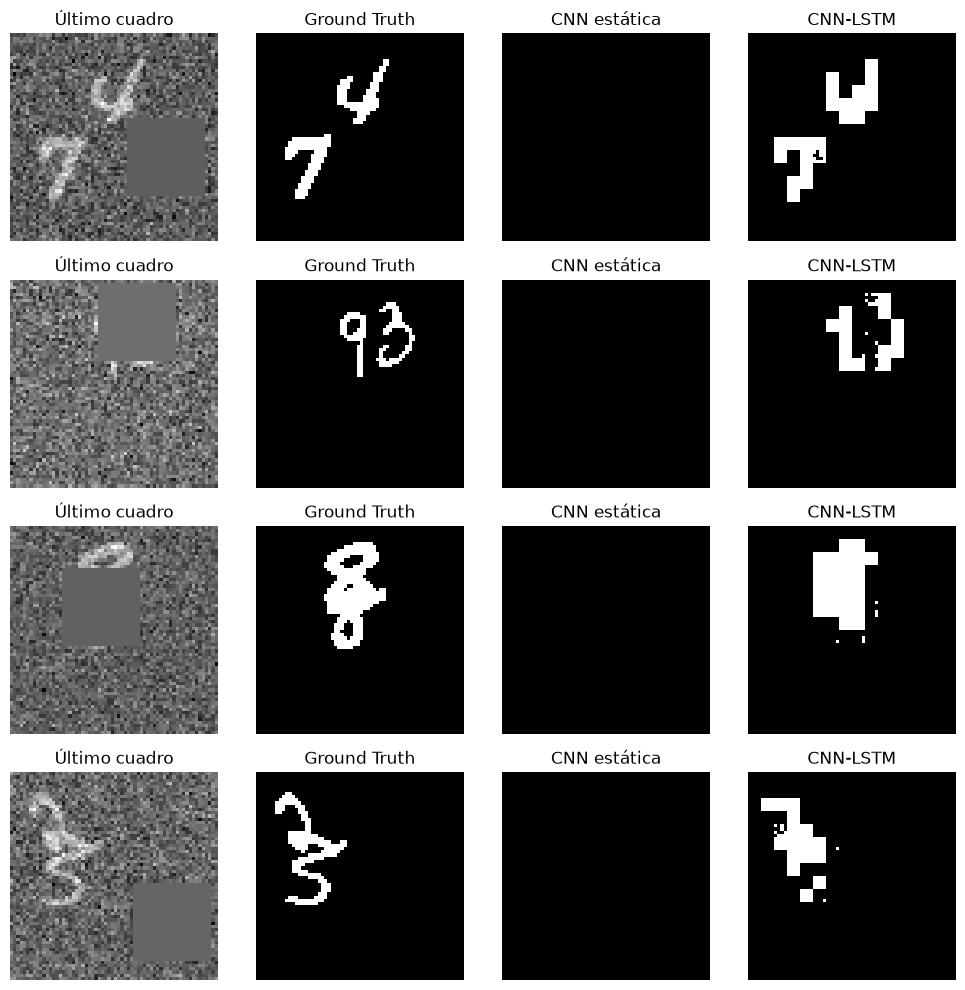

In [19]:
x, y = next(iter(vid_test))
with torch.no_grad():
    p_est = cnn_est(x.to(DEVICE)).argmax(1).cpu()
    p_lstm = cnn_lstm(x.to(DEVICE)).argmax(1).cpu()

fig, axs = plt.subplots(4, 4, figsize=(10, 10))
for i in range(4):
    for j, (img, tit) in enumerate([(x[i, -1, 0], "Último cuadro"), (y[i], "Ground Truth"),
                                    (p_est[i], "CNN estática"), (p_lstm[i], "CNN-LSTM")]):
        axs[i, j].imshow(img, cmap="gray"); axs[i, j].set_title(tit); axs[i, j].axis("off")
plt.tight_layout(); plt.show()

In [20]:
delta_video = res_lstm["iou"][1]-res_est["iou"][1]
display(Markdown(f"**Respuesta:** la diferencia CNN-LSTM menos CNN en IoU de dígito es **{delta_video:+.4f}** en prueba. "
                 f"Dentro de las oclusiones: CNN {oc_est:.4f}, CNN-LSTM {oc_lstm:.4f}. "
                 "La LSTM puede aprovechar observaciones anteriores para reducir ruido y reconstruir partes ocluidas. "
                 "No garantiza mejorar: los dígitos cambian de posición y esta LSTM integra por posición espacial, sin alinear movimiento. "
                 "También agrega parámetros y cómputo; esta comparación no aísla completamente el efecto de capacidad. "
                 "La afirmación sobre cuál funciona mejor queda limitada a estas métricas, cinco épocas y una semilla."))

**Respuesta:** la diferencia CNN-LSTM menos CNN en IoU de dígito es **+0.4715** en prueba. Dentro de las oclusiones: CNN 0.0000, CNN-LSTM 0.3128. La LSTM puede aprovechar observaciones anteriores para reducir ruido y reconstruir partes ocluidas. No garantiza mejorar: los dígitos cambian de posición y esta LSTM integra por posición espacial, sin alinear movimiento. También agrega parámetros y cómputo; esta comparación no aísla completamente el efecto de capacidad. La afirmación sobre cuál funciona mejor queda limitada a estas métricas, cinco épocas y una semilla.

# PARTE D — Segmentación del hipocampo en MRI 3D

El [tutorial RISE](https://github.com/BioMedIA-MBZUAI/RISE-Summer-School/blob/main/Day_3_Hippocampus_Segmentation.ipynb) utiliza LISA, MRI de campo ultrabajo, MONAI y segmentación bilateral. Su descarga SharePoint devolvió HTTP 401 en esta sesión. Se implementa una adaptación **3D real**, con volúmenes NIfTI públicos de [MSD Task04_Hippocampus](https://msd-for-monai.s3-us-west-2.amazonaws.com/Task04_Hippocampus.tar).

**Diferencias:** Task04 proporciona recortes del hipocampo, no cerebros completos LISA. Las etiquetas son `0 fondo`, `1 anterior`, `2 posterior` según `dataset.json`; el desbalance y la dificultad no equivalen a LISA. No se presentan estos resultados como reproducción de sus resultados.

Se conserva la orientación canónica de NIfTI, se aplica normalización por volumen y se remuestrea a 32³ para un experimento local compacto (trilineal en imagen y vecino más cercano en máscara). La división se hace por identificador de caso antes de formar los loaders, sin mezclar cortes del mismo volumen. No se verificó independencia por paciente: MSD incluye recortes de ambos hipocampos y no se reconstruyó su agrupación por sujeto. Las métricas se calculan en esta rejilla remuestreada, no en resolución clínica original. Se selecciona checkpoint por validación y se evalúa prueba una sola vez.

Etiquetas originales: {'0': 'background', '1': 'Anterior', '2': 'Posterior'}


Casos: entrenamiento 182, validación 39, prueba 39


,Clase,Fracción de voxeles train
0,Fondo,0.947421
1,Anterior,0.027288
2,Posterior,0.025291


Hipocampo 3D | 1/8 | loss 1.4609 | val mIoU 0.5226 | 6.8s


Hipocampo 3D | 2/8 | loss 1.1526 | val mIoU 0.6216 | 6.8s


Hipocampo 3D | 3/8 | loss 1.0232 | val mIoU 0.6114 | 6.9s


... (3 outputs left out)

Hipocampo 3D | 7/8 | loss 0.6479 | val mIoU 0.7344 | 6.9s


Hipocampo 3D | 8/8 | loss 0.5761 | val mIoU 0.7122 | 7.0s


,Clase,IoU,Dice,Recall
0,Fondo,0.9718,0.9857,0.9737
1,Anterior,0.6367,0.7780,0.9240
2,Posterior,0.6023,0.7518,0.9429


**Hipocampo, prueba:** mIoU global 0.7369; Dice macro sin fondo (matriz global) 0.7649; Dice promedio por caso y región 0.7636 ± 0.0414 (desviación entre casos, no intervalo de confianza). Los recortes y la reducción a 32³ limitan la extrapolación. Para reproducir LISA harían falta sus datos autorizados, etiquetas bilaterales, preprocesamiento original y evaluación en su resolución de referencia.

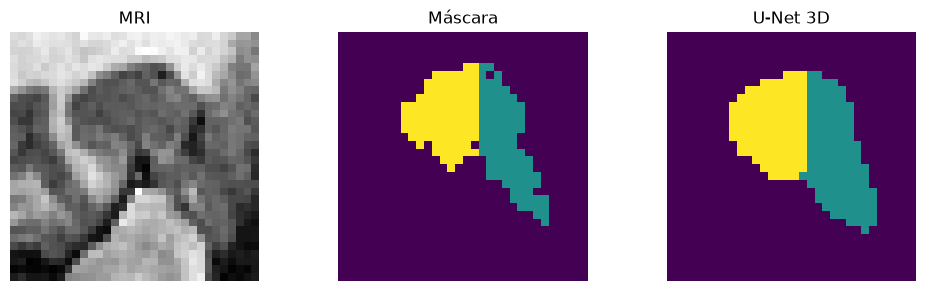

In [21]:
import nibabel as nib
hip_tar = DATA / "Task04_Hippocampus.tar"
hip_dir = DATA / "Task04_Hippocampus"
if not (hip_dir / "dataset.json").exists():
    if not hip_tar.exists():
        urllib.request.urlretrieve("https://msd-for-monai.s3-us-west-2.amazonaws.com/Task04_Hippocampus.tar",hip_tar)
    with tarfile.open(hip_tar) as t:
        t.extractall(DATA, filter="data")
meta_hip = json.loads((hip_dir / "dataset.json").read_text())
print("Etiquetas originales:",meta_hip["labels"])
casos_hip = sorted(p for p in (hip_dir / "imagesTr").glob("*.nii.gz") if not p.name.startswith("._"))
rng = np.random.default_rng(SEED); rng.shuffle(casos_hip)
n_hip = len(casos_hip); n_tr,n_va = int(.7*n_hip),int(.15*n_hip)
hip_train,hip_val,hip_test = casos_hip[:n_tr],casos_hip[n_tr:n_tr+n_va],casos_hip[n_tr+n_va:]
assert not set(hip_train)&set(hip_val) and not set(hip_train)&set(hip_test) and not set(hip_val)&set(hip_test)
def cargar_hip(paths):
    xs,ys=[],[]
    for p in paths:
        im=nib.as_closest_canonical(nib.load(p))
        mask=nib.as_closest_canonical(nib.load(hip_dir / "labelsTr" / p.name))
        assert im.shape == mask.shape and np.allclose(im.affine,mask.affine)
        a=np.asarray(im.dataobj,dtype=np.float32).copy()
        a=(a-a.mean())/max(float(a.std()),1e-6)
        b=np.asarray(mask.dataobj,dtype=np.int64).copy()
        assert set(np.unique(b)).issubset({0,1,2})
        xs.append(F.interpolate(torch.from_numpy(a)[None,None],size=(32,32,32),mode="trilinear",align_corners=False)[0])
        ys.append(F.interpolate(torch.from_numpy(b).float()[None,None],size=(32,32,32),mode="nearest")[0,0].long())
    return TensorDataset(torch.stack(xs),torch.stack(ys))
ds_hip_tr,ds_hip_va,ds_hip_te = [cargar_hip(p) for p in [hip_train,hip_val,hip_test]]
ld_hip_tr=DataLoader(ds_hip_tr,batch_size=8,shuffle=True,generator=torch.Generator().manual_seed(SEED))
ld_hip_va=DataLoader(ds_hip_va,batch_size=8);ld_hip_te=DataLoader(ds_hip_te,batch_size=8)
print(f"Casos: entrenamiento {len(hip_train)}, validación {len(hip_val)}, prueba {len(hip_test)}")
NOMBRES_HIP=["Fondo","Anterior","Posterior"]
count_hip=torch.bincount(ds_hip_tr.tensors[1].flatten(),minlength=3).float()
display(pd.DataFrame({"Clase":NOMBRES_HIP,"Fracción de voxeles train":(count_hip/count_hip.sum()).numpy()}))
class Bloque3D(nn.Module):
    def __init__(self,entrada,salida):
        super().__init__()
        self.net=nn.Sequential(nn.Conv3d(entrada,salida,3,padding=1,bias=False),nn.GroupNorm(4,salida),nn.ReLU(),
                               nn.Conv3d(salida,salida,3,padding=1,bias=False),nn.GroupNorm(4,salida),nn.ReLU())
    def forward(self,x):return self.net(x)
class UNetHipocampo3D(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1=Bloque3D(1,8);self.e2=Bloque3D(8,16);self.b=Bloque3D(16,32)
        self.pool=nn.MaxPool3d(2)
        self.d2=Bloque3D(48,16);self.d1=Bloque3D(24,8);self.out=nn.Conv3d(8,3,1)
    def forward(self,x):
        s1=self.e1(x);s2=self.e2(self.pool(s1));b=self.b(self.pool(s2))
        d2=self.d2(torch.cat([F.interpolate(b,size=s2.shape[2:],mode="trilinear",align_corners=False),s2],1))
        d1=self.d1(torch.cat([F.interpolate(d2,size=s1.shape[2:],mode="trilinear",align_corners=False),s1],1))
        return self.out(d1)
# CPU evita depender de cobertura de operadores 3D en versiones diferentes de MPS.
HIP_DEVICE="cuda" if torch.cuda.is_available() else "cpu"
fijar_semilla();modelo_hip=UNetHipocampo3D().to(HIP_DEVICE)
assert modelo_hip(torch.zeros(1,1,32,32,32,device=HIP_DEVICE)).shape == (1,3,32,32,32)
w_hip=(1/count_hip);w_hip=w_hip/w_hip.mean()
ce_hip=nn.CrossEntropyLoss(weight=w_hip.to(HIP_DEVICE))
def perdida_hip(logits,y):return ce_hip(logits,y)+dice_fn(logits,y)
hist_hip,ep_hip=entrenar_modelo(modelo_hip,ld_hip_tr,ld_hip_va,perdida_hip,3,"Hipocampo 3D",epochs=8,device=HIP_DEVICE)
res_hip=evaluar_modelo(modelo_hip,ld_hip_te,3,HIP_DEVICE)
display(tabla_metricas(res_hip,NOMBRES_HIP).round(4))
# Dice por volumen sin fondo: complementa la matriz global, que pondera por número de voxeles.
dice_por_caso=[]
for x,y in DataLoader(ds_hip_te,batch_size=1):
    with torch.no_grad():p=modelo_hip(x.to(HIP_DEVICE)).argmax(1).cpu()
    dice_por_caso.append([float(2*((p==c)&(y==c)).sum()/((p==c).sum()+(y==c).sum()).clamp_min(1)) for c in [1,2]])
dice_por_caso=np.array(dice_por_caso)
display(Markdown(f"**Hipocampo, prueba:** mIoU global {res_hip['miou']:.4f}; Dice macro sin fondo (matriz global) {res_hip['dice'][1:].mean():.4f}; "
                 f"Dice promedio por caso y región {dice_por_caso.mean():.4f} ± {dice_por_caso.mean(1).std():.4f} (desviación entre casos, no intervalo de confianza). "
                 "Los recortes y la reducción a 32³ limitan la extrapolación. Para reproducir LISA harían falta sus datos autorizados, "
                 "etiquetas bilaterales, preprocesamiento original y evaluación en su resolución de referencia."))
xh,yh=ds_hip_te[0]
with torch.no_grad():ph=modelo_hip(xh[None].to(HIP_DEVICE)).argmax(1)[0].cpu()
z=int((yh>0).sum((0,1)).argmax())
fig,axs=plt.subplots(1,3,figsize=(10,3))
for ax,img,title in zip(axs,[xh[0,:,:,z],yh[:,:,z],ph[:,:,z]],["MRI","Máscara","U-Net 3D"]):
    ax.imshow(img,cmap="gray" if title=="MRI" else "viridis",vmin=None if title=="MRI" else 0,vmax=None if title=="MRI" else 2)
    ax.set_title(title);ax.axis("off")
plt.tight_layout();plt.show()

# PARTE E — Clasificación con datos desbalanceados (TensorFlow/Keras)

Adaptación ejecutable del [tutorial oficial de fraude](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data): se conserva el dataset de transacciones, la red densa de 16 unidades con dropout 0.5 y Adam. Se comparan modelo base, pesos inversos a frecuencia y sobremuestreo con reemplazo de la clase positiva. Cada estrategia recibe el mismo número de actualizaciones, la misma inicialización y cinco épocas; el experimento es breve y no replica todo el ajuste de hiperparámetros del tutorial.

Se usa partición estratificada 64/16/20. El estandarizador se ajusta solo con entrenamiento; se elimina `Time`, se transforma `Amount` con logaritmo y se recorta a [-5,5]. El umbral se elige maximizando F1 **en validación**, y se fija antes de evaluar prueba. AP resume precision-recall; ROC-AUC y exactitud se reportan junto con precision/recall para evitar ocultar fraudes omitidos. No se equipara AP con el área trapezoidal de la curva PR.

,Partición,Total,Fraudes,Fracción fraude
0,Train,182276,315,0.001728
1,Val,45569,79,0.001734
2,Test,56962,98,0.001720


Epoch 1/5


/Users/vikingo/Documents/UDG2/5toSem/DeepLearning/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


90/90 - 1s - 7ms/step - loss: 0.0175 - val_loss: 0.0103


Epoch 2/5


90/90 - 0s - 3ms/step - loss: 0.0093 - val_loss: 0.0051


... (25 outputs left out)

90/90 - 0s - 3ms/step - loss: 0.3562 - val_loss: 0.0583


Epoch 5/5


90/90 - 0s - 3ms/step - loss: 0.3251 - val_loss: 0.0682


,Estrategia,Umbral,Valor umbral,Precision,Recall,F1,Exactitud,AP,ROC-AUC,TN,FP,FN,TP
0,Base,0.5,0.5000,0.8625,0.7041,0.7753,0.9993,0.7832,0.9674,56853,11,29,69
1,Base,Elegido en val,0.1324,0.8602,0.8163,0.8377,0.9995,0.7832,0.9674,56851,13,18,80
2,Pesos,0.5,0.5000,0.1938,0.8980,0.3188,0.9934,0.7114,0.9743,56498,366,10,88
3,Pesos,Elegido en val,0.9968,0.8261,0.7755,0.8000,0.9993,0.7114,0.9743,56848,16,22,76
4,Sobremuestreo,0.5,0.5000,0.0801,0.9286,0.1475,0.9815,0.7451,0.9851,55819,1045,7,91
5,Sobremuestreo,Elegido en val,0.9998,0.8144,0.8061,0.8103,0.9994,0.7451,0.9851,56846,18,19,79


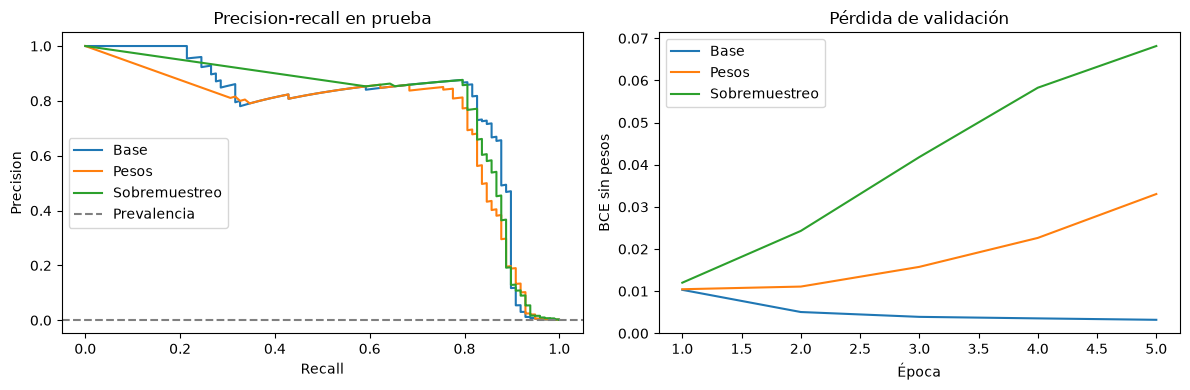

**Interpretación:** predecir siempre 'no fraude' daría exactitud 99.8280% y recall de fraude 0. Los pesos y el sobremuestreo aumentan la importancia de los positivos durante el aprendizaje; pueden cambiar precision y recall y requieren ajustar el umbral. El umbral de cada estrategia se decidió con validación, sin consultar etiquetas de prueba. El costo operativo de FP frente a FN no fue especificado: F1 es una elección didáctica, no una política de producción.

In [22]:
# Liberar modelos de GPU que ya tienen métricas y gráficas guardadas.
for m in list(modelos_pet.values())+[modelo_k,cnn_est,cnn_lstm]:m.to("cpu")
if DEVICE=="mps":torch.mps.empty_cache()
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (precision_recall_curve,precision_score,recall_score,f1_score,
                             average_precision_score,roc_auc_score,accuracy_score,confusion_matrix)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.threading.set_intra_op_parallelism_threads(6)
tf.keras.utils.set_random_seed(SEED)
csv_fraude=DATA / "creditcard.csv"
if not csv_fraude.exists():
    urllib.request.urlretrieve("https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv",csv_fraude)
fraude=pd.read_csv(csv_fraude)
y_f=fraude["Class"].to_numpy(dtype=np.int64)
xf=fraude.drop(columns=["Class","Time"]).copy()
xf["Amount"]=np.log(xf["Amount"]+.001)
indices=np.arange(len(y_f))
idx_trva,idx_te=train_test_split(indices,test_size=.2,stratify=y_f,random_state=SEED)
idx_tr,idx_va=train_test_split(idx_trva,test_size=.2,stratify=y_f[idx_trva],random_state=SEED)
assert not set(idx_tr)&set(idx_va) and not set(idx_tr)&set(idx_te) and not set(idx_va)&set(idx_te)
scaler=StandardScaler().fit(xf.iloc[idx_tr])
Xf=np.clip(scaler.transform(xf),-5,5).astype(np.float32)
Xtr,Xva,Xte=Xf[idx_tr],Xf[idx_va],Xf[idx_te]
ytr,yva,yte=y_f[idx_tr],y_f[idx_va],y_f[idx_te]
display(pd.DataFrame([{"Partición":name,"Total":len(y),"Fraudes":int(y.sum()),"Fracción fraude":float(y.mean())}
                     for name,y in [("Train",ytr),("Val",yva),("Test",yte)]]))
def crear_clasificador():
    tf.keras.utils.set_random_seed(SEED)
    m=tf.keras.Sequential([tf.keras.layers.Input((Xtr.shape[1],)),tf.keras.layers.Dense(16,activation="relu"),
                           tf.keras.layers.Dropout(.5),tf.keras.layers.Dense(1,activation="sigmoid",
                           bias_initializer=tf.keras.initializers.Constant(float(np.log(ytr.mean()/(1-ytr.mean())))))])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss="binary_crossentropy")
    return m
base_f=crear_clasificador();inicio_f=base_f.get_weights()
conteo_f=np.bincount(ytr,minlength=2);pesos_f=len(ytr)/(2*conteo_f)
rng_f=np.random.default_rng(SEED)
pos=np.flatnonzero(ytr==1);neg=np.flatnonzero(ytr==0)
balanceados=np.concatenate([rng_f.choice(pos,len(ytr)//2,replace=True),rng_f.choice(neg,len(ytr)-len(ytr)//2,replace=True)])
rng_f.shuffle(balanceados)
predicciones_f={};hist_f={};umbrales_f={};filas_f=[]
for estrategia in ["Base","Pesos","Sobremuestreo"]:
    m=crear_clasificador();m.set_weights(inicio_f)
    train_ix=balanceados if estrategia=="Sobremuestreo" else np.arange(len(ytr))
    weights=pesos_f[ytr[train_ix]].astype(np.float32) if estrategia=="Pesos" else np.ones(len(train_ix),np.float32)
    ds=tf.data.Dataset.from_tensor_slices((Xtr[train_ix],ytr[train_ix],weights)).shuffle(len(train_ix),seed=SEED).batch(2048)
    options=tf.data.Options();options.threading.private_threadpool_size=2;ds=ds.with_options(options)
    val_ds_fraude=tf.data.Dataset.from_tensor_slices((Xva,yva)).batch(4096).with_options(options)
    h=m.fit(ds,validation_data=val_ds_fraude,epochs=5,verbose=2)
    hist_f[estrategia]=h.history
    pv=m.predict(Xva,batch_size=4096,verbose=0).ravel()
    precision,recall,thresholds=precision_recall_curve(yva,pv)
    f1s=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
    umbral=float(thresholds[np.argmax(f1s)])
    umbrales_f[estrategia]=umbral
    pt=m.predict(Xte,batch_size=4096,verbose=0).ravel();predicciones_f[estrategia]=pt
    for nombre_umbral,t in [("0.5",.5),("Elegido en val",umbral)]:
        yp=pt>=t;cm_f=confusion_matrix(yte,yp,labels=[0,1]);tn,fp,fn,tp=cm_f.ravel()
        filas_f.append({"Estrategia":estrategia,"Umbral":nombre_umbral,"Valor umbral":t,"Precision":precision_score(yte,yp,zero_division=0),
                        "Recall":recall_score(yte,yp,zero_division=0),"F1":f1_score(yte,yp,zero_division=0),
                        "Exactitud":accuracy_score(yte,yp),"AP":average_precision_score(yte,pt),"ROC-AUC":roc_auc_score(yte,pt),
                        "TN":tn,"FP":fp,"FN":fn,"TP":tp})
tabla_fraude=pd.DataFrame(filas_f)
display(tabla_fraude.round(4));tabla_fraude.to_csv(RESULTADOS / "fraude_comparacion.csv",index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for nombre,pt in predicciones_f.items():
    pr,re,_=precision_recall_curve(yte,pt);axs[0].plot(re,pr,label=nombre)
    axs[1].plot(range(1,6),hist_f[nombre]["val_loss"],label=nombre)
axs[0].axhline(yte.mean(),color="gray",linestyle="--",label="Prevalencia")
axs[0].set(xlabel="Recall",ylabel="Precision",title="Precision-recall en prueba")
axs[1].set(xlabel="Época",ylabel="BCE sin pesos",title="Pérdida de validación")
for ax in axs:ax.legend()
plt.tight_layout();plt.show()
display(Markdown(f"**Interpretación:** predecir siempre 'no fraude' daría exactitud {1-yte.mean():.4%} y recall de fraude 0. "
                 "Los pesos y el sobremuestreo aumentan la importancia de los positivos durante el aprendizaje; pueden cambiar precision y recall "
                 "y requieren ajustar el umbral. El umbral de cada estrategia se decidió con validación, sin consultar etiquetas de prueba. "
                 "El costo operativo de FP frente a FN no fue especificado: F1 es una elección didáctica, no una política de producción."))

# PARTE F — Revisión crítica de U-Net y variantes

**Referencia corregida:** Wang Jiangtao, Nur Intan Raihana Ruhaiyem y Fu Panpan (2025). *A Comprehensive Review of U-Net and Its Variants: Advances and Applications in Medical Image Segmentation*. arXiv:2502.06895. [Registro](https://arxiv.org/abs/2502.06895), [texto completo](https://arxiv.org/pdf/2502.06895). La autoría proporcionada en el enunciado no coincide con el registro.

El artículo organiza los avances mediante conexiones de salto, conexiones residuales, U-Net 3D y mecanismos Transformer. Su contribución es relacionar cambios arquitectónicos, modalidades médicas y limitaciones de las propuestas revisadas. Los saltos recuperan detalle espacial; las conexiones residuales facilitan optimización; los modelos 3D incorporan contexto entre cortes; los Transformers exploran dependencias amplias. Estas estrategias implican diferentes necesidades de memoria y datos.

| Familia / ejemplo | Cambio principal | Compromiso |
|---|---|---|
| Saltos densos: UNet++ | Fusionar características entre escalas | Mayor complejidad de fusión |
| Residual: Res-UNet | Aprender correcciones mediante sumas residuales | No resuelve por sí sola el cambio de dominio |
| 3D U-Net | Convoluciones volumétricas | Mayor memoria y dependencia del espaciado |
| Híbrida: TransUNet | CNN y atención global | Más cómputo; conservar precisión de bordes |

**Lectura crítica propia:** una revisión de arquitecturas no demuestra cuál ganará en nuestro conjunto. Comparar cifras de trabajos con particiones, resoluciones o protocolos distintos no establece una clasificación universal. Se necesitan ablaciones controladas, separación por paciente, métricas por estructura, estimación de variabilidad y validación externa.

**Relación con el laboratorio:** se aísla el aporte informativo de los saltos; se compara la pérdida manteniendo arquitectura y presupuesto; se pasa de imágenes 2D a volúmenes 3D; se excluye el fondo al resumir Dice del hipocampo. No se entrenan variantes residuales ni Transformers: se discuten como extensiones, sin atribuirles resultados experimentales propios.

## Relación con los tutoriales

| Recurso | Aplicación en esta entrega | Diferencia explícita |
|---|---|---|
| TensorFlow: segmentación | Oxford-IIIT Pet, etiquetas por píxel, encoder-decoder y ponderación | U-Net compacta PyTorch desde cero; el tutorial usa MobileNetV2 preentrenada |
| TensorFlow: desbalance | Fraude con Keras, pesos, sobremuestreo, precision/recall y umbral | Cinco épocas, presupuesto de actualizaciones igualado; no reproduce todo el ajuste del tutorial |
| RISE: hipocampo | MRI NIfTI, U-Net 3D, Dice y particiones por caso | MSD anterior/posterior; LISA bilateral no accesible sin autorización |
| Revisión 2025 | Síntesis, crítica y relación con las ablaciones | Sin afirmar superioridad universal de una variante |

## Limitaciones

Una semilla por experimento, entrenamiento breve, subconjuntos de Pets y Moving MNIST y rejilla 3D reducida. En MPS pueden existir diferencias numéricas entre ejecuciones aun fijando semillas. Pets se selecciona con validación separada de entrenamiento y se informa prueba oficial; Kvasir no ofrece aquí identificadores de paciente. Los resultados no demuestran utilidad clínica ni equivalencia con LISA. Para mayor robustez: repetir varias semillas, conservar resolución física, medir incertidumbre por caso y evaluar datos externos.

## Bibliografía

1. TensorFlow. [Image segmentation](https://www.tensorflow.org/tutorials/images/segmentation?hl=es-419).
2. TensorFlow. [Classification on imbalanced data](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data).
3. BioMedIA-MBZUAI. [Day 3: Hippocampus Segmentation](https://github.com/BioMedIA-MBZUAI/RISE-Summer-School/blob/main/Day_3_Hippocampus_Segmentation.ipynb).
4. Wang Jiangtao, Nur Intan Raihana Ruhaiyem y Fu Panpan (2025). [arXiv:2502.06895](https://arxiv.org/abs/2502.06895).
5. Ronneberger, O., Fischer, P. y Brox, T. (2015). [U-Net: Convolutional Networks for Biomedical Image Segmentation](https://arxiv.org/abs/1505.04597).
6. Antonelli et al. (2022). [The Medical Segmentation Decathlon](https://doi.org/10.1038/s41467-022-30695-9).
7. Jha et al. (2020). [Kvasir-SEG: A Segmented Polyp Dataset](https://arxiv.org/abs/1911.07069).
8. Srivastava, N., Mansimov, E. y Salakhutdinov, R. (2015). [Unsupervised Learning of Video Representations using LSTMs](https://arxiv.org/abs/1502.04681).
9. Parkhi et al. (2012). [Cats and Dogs — Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/).

In [23]:
# Comprobación final de evidencia numérica y exportación del resumen.
assert cm.sum() == len(val_ds)*TAM*TAM
assert np.allclose(iou_manual,ious,atol=1e-6)
assert np.isclose(iou_manual.mean(),miou,atol=1e-6)
assert np.allclose(base["dice"],2*base["iou"]/(1+base["iou"]))
assert len(tabla_experimentos)==5 and len(tabla_fraude)==6
assert all(np.isfinite(r["iou"]).all() for r in [*evaluaciones_pet.values(),test_pet,resultado_k,res_est,res_lstm,res_hip])
resumen={"seed":SEED,"device":DEVICE,"pets_mejor_validacion":mejor_nombre,"pets_miou_test":test_pet["miou"],
         "kvasir_miou_test":resultado_k["miou"],"video_iou_digito_cnn":float(res_est["iou"][1]),
         "video_iou_digito_lstm":float(res_lstm["iou"][1]),"hipocampo_miou_test":res_hip["miou"],
         "hipocampo_dice_sin_fondo":float(res_hip["dice"][1:].mean()),"hipocampo_dataset":"MSD Task04; LISA HTTP 401",
         "fraude_umbrales_validacion":umbrales_f,"torch":torch.__version__,"tensorflow":tf.__version__}
(RESULTADOS / "resumen.json").write_text(json.dumps(resumen,indent=2,ensure_ascii=False))
for name,h in historias.items():h.to_csv(RESULTADOS / (name.replace(" ","_").replace("+","mas")+"_historia.csv"),index=False)
hist_hip.to_csv(RESULTADOS / "hipocampo_historia.csv",index=False)
tabla_metricas(res_hip,NOMBRES_HIP).to_csv(RESULTADOS / "hipocampo_test.csv",index=False)
print("Verificación final: métricas coherentes, resultados finitos y tablas exportadas.")
display(pd.DataFrame([resumen]))

Verificación final: métricas coherentes, resultados finitos y tablas exportadas.


,seed,device,pets_mejor_validacion,pets_miou_test,kvasir_miou_test,video_iou_digito_cnn,video_iou_digito_lstm,hipocampo_miou_test,hipocampo_dice_sin_fondo,hipocampo_dataset,fraude_umbrales_validacion,torch,tensorflow
0,2,mps,Dice,0.628796,0.638772,0.0,0.471475,0.736943,0.764915,MSD Task04; LISA HTTP 401,"{'Base': 0.1324247568845749, 'Pesos': 0.996803...",2.14.1,2.21.0
